<a href="https://colab.research.google.com/github/cpt0/data201-labs/blob/main/data201-Project1/PROJECT_three_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     KFold, StratifiedKFold, LeaveOneOut, GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import mean_squared_error, roc_auc_score

from sklearn.model_selection import (
    train_test_split, cross_val_score, StratifiedKFold
)

from sklearn.preprocessing import (
    OneHotEncoder, StandardScaler, MinMaxScaler,
    RobustScaler, Normalizer, KBinsDiscretizer,
    FunctionTransformer
)

In [3]:


file_path = "/content/drive/MyDrive/DATA 201/Datasets/heart.csv"

heart = pd.read_csv(file_path)

heart.head()



,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [4]:
heart["target"].value_counts()

,count
target,
1,526
0,499


In [5]:
heart.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


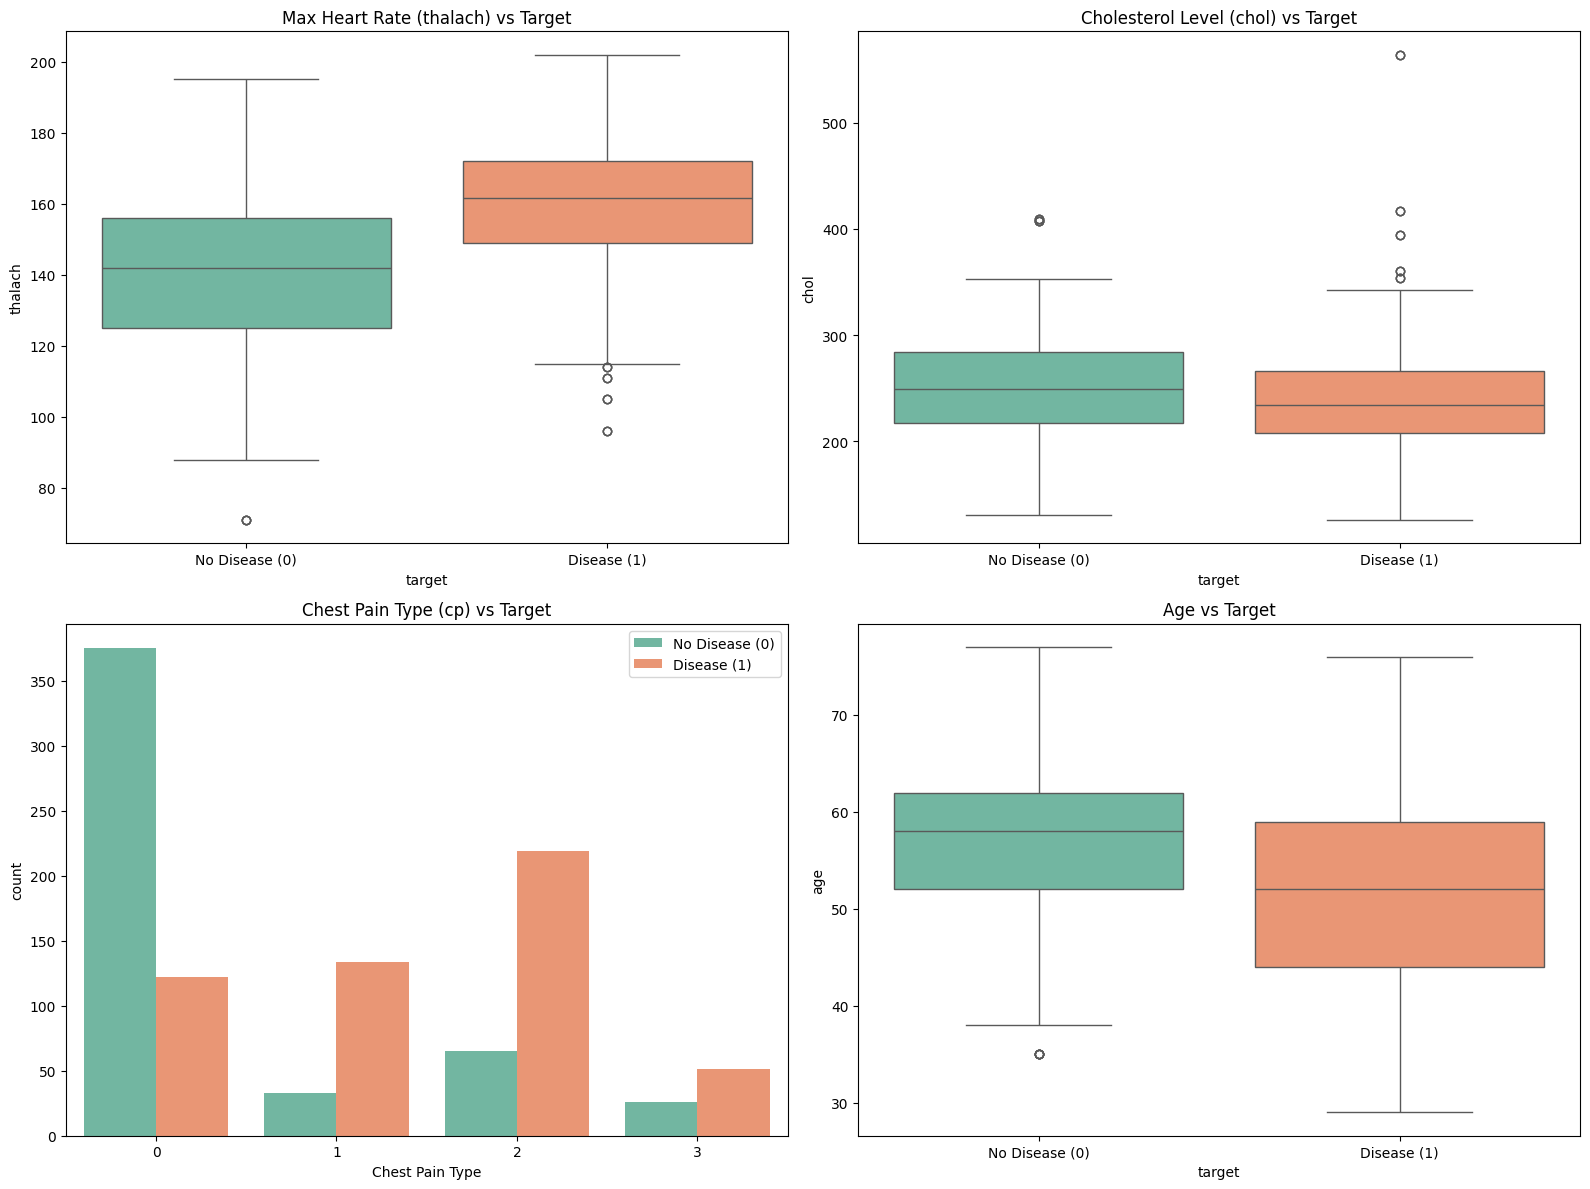

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set up a 2x2 grid of subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Boxplot of Max Heart Rate (thalach) vs Target
sns.boxplot(ax=axes[0, 0], x='target', y='thalach', hue='target', data=heart, palette='Set2', legend=False)
axes[0, 0].set_title('Max Heart Rate (thalach) vs Target')
axes[0, 0].set_xticks([0, 1])
axes[0, 0].set_xticklabels(['No Disease (0)', 'Disease (1)'])

# 2. Boxplot of Cholesterol (chol) vs Target
sns.boxplot(ax=axes[0, 1], x='target', y='chol', hue='target', data=heart, palette='Set2', legend=False)
axes[0, 1].set_title('Cholesterol Level (chol) vs Target')
axes[0, 1].set_xticks([0, 1])
axes[0, 1].set_xticklabels(['No Disease (0)', 'Disease (1)'])

# 3. Count plot of Chest Pain Type (cp) grouped by Target
sns.countplot(ax=axes[1, 0], x='cp', hue='target', data=heart, palette='Set2')
axes[1, 0].set_title('Chest Pain Type (cp) vs Target')
axes[1, 0].set_xlabel('Chest Pain Type')
axes[1, 0].legend(['No Disease (0)', 'Disease (1)'])

# 4. Boxplot of Age vs Target
sns.boxplot(ax=axes[1, 1], x='target', y='age', hue='target', data=heart, palette='Set2', legend=False)
axes[1, 1].set_title('Age vs Target')
axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_xticklabels(['No Disease (0)', 'Disease (1)'])

plt.tight_layout()
plt.show()

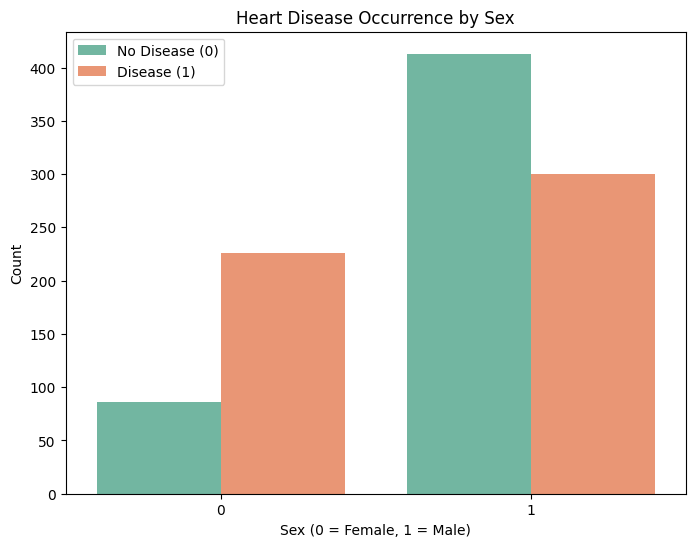

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.countplot(x='sex', hue='target', data=heart, palette='Set2')
plt.title('Heart Disease Occurrence by Sex')
plt.xlabel('Sex (0 = Female, 1 = Male)')
plt.ylabel('Count')
plt.legend(['No Disease (0)', 'Disease (1)'])
plt.show()

1. What does each row of your dataset represent? What is your response variable? What are its possible classes?

What each row represents is a patient the response variable is the target which is whether or not they have heart disease which is shown by 1s and 0s.


2. Select the predictors you believe could be useful for classification.
age, sex, thalach, cp, fbs. Based on the graphs above due to the different variation between no disease and disease.


3. Examine the distribution of your response variable.
 How many observations belong to each class?
 Using value.counts() we can see that
 526 belong to yes/1
 499 belong to no/0
 Is the dataset reasonably balanced or imbalanced?
 It is balanced

4. Define a false positive and false negative in the context of your dataset.

False Positive
It predicts they have heart disease but they don't

False Negative
It predicts that they don't have heart disease and they do

5. Which type of error would you be more concerned about in this application, or are they
similarly important? Explain your reasoning.

False Negative would be worse, because it would say that someone doesn't have heart disease but they actually do so they might not get treatment which could be fatal.

The reason this isn't as bad as a false positive is becasue although there is panic, the extra testing would show that the patient is safe.

In [8]:
heart[['age', 'sex', 'cp', 'thalach', 'oldpeak', 'ca', 'exang', 'slope','thal']].describe()

,age,sex,cp,thalach,oldpeak,ca,exang,slope,thal
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,149.114146,1.071512,0.754146,0.336585,1.385366,2.323902
std,9.072290,0.460373,1.029641,23.005724,1.175053,1.030798,0.472772,0.617755,0.620660
min,29.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,132.000000,0.000000,0.000000,0.000000,1.000000,2.000000
50%,56.000000,1.000000,1.000000,152.000000,0.800000,0.000000,0.000000,1.000000,2.000000
75%,61.000000,1.000000,2.000000,166.000000,1.800000,1.000000,1.000000,2.000000,3.000000
max,77.000000,1.000000,3.000000,202.000000,6.200000,4.000000,1.000000,2.000000,3.000000


Part 2

1. Investigate your features and predictors.


2. Determine whether your dataset contains missing values. If it does, explain how you
handled them.
So we used isna().sum as we as the sum of that same function. And we saw there were no na's meaning there wasn't much to do. However thal had 0's

3. Determine whether any categorical predictors need to be encoded before modeling.
There was no need for encoding.

4. Divide the data, then use k-fold CV on training data.


5. Determine whether predictors should be standardized for any of the classifiers you will
use.
Yes it was needed for age and thalach.

In [9]:
heart.isna().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [10]:
X = heart[["age","thalach","cp","fbs","sex"]]
y = heart["target"]

In [11]:
# Split the data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25, #this is the default %, you can remove this line if you want to
    random_state=99,

)

In [12]:
# Split the data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25, #this is the default %, you can remove this line if you want to
    random_state=99,


)


In [13]:
# Build preprocessing steps
preprocess = make_pipeline(
    StandardScaler()
)

# Combine preprocessing with logistic regression
def pipeline(classification_model):
  pipe = make_pipeline(
      preprocess,
      classification_model
  )
  return pipe

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=4
)

# KNN without scaling
def cross_validation(classification_model):
  scores = cross_val_score(
      classification_model,
      X_train,
      y_train,
      cv=cv,
      scoring="accuracy"
  )
  return scores.mean()

In [14]:
cross_validation(LogisticRegression(max_iter=2000))

np.float64(0.7578134284016637)

In [15]:
cross_validation(LinearDiscriminantAnalysis())

np.float64(0.7538918597742127)

In [16]:
cross_validation(QuadraticDiscriminantAnalysis())

np.float64(0.7655971479500892)

In [17]:

knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier()
)

knn_grid = {
    'kneighborsclassifier__n_neighbors': [1, 3, 5, 11, 21, 31, 41, 51, 59, 71, 101],
    'kneighborsclassifier__weights': ['uniform','distance']
}

grid_knn = GridSearchCV(
    knn,
    knn_grid,
    cv=5,
    scoring='roc_auc'
)

grid_knn.fit(X_train, y_train)

print("KNN best parameters:", grid_knn.best_params_)
print("KNN best CV ROC and AUC:", round(grid_knn.best_score_, 4))

KNN best parameters: {'kneighborsclassifier__n_neighbors': 59, 'kneighborsclassifier__weights': 'distance'}
KNN best CV ROC and AUC: 0.9974


In [18]:

k_values = [1, 3, 5, 11, 21, 31, 41, 51, 59, 71, 101]

#create an empty list
cv_scores = []

#Run cross-validation
for k in k_values:

    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring = 'roc_auc'
    )

    cv_scores.append(scores.mean())





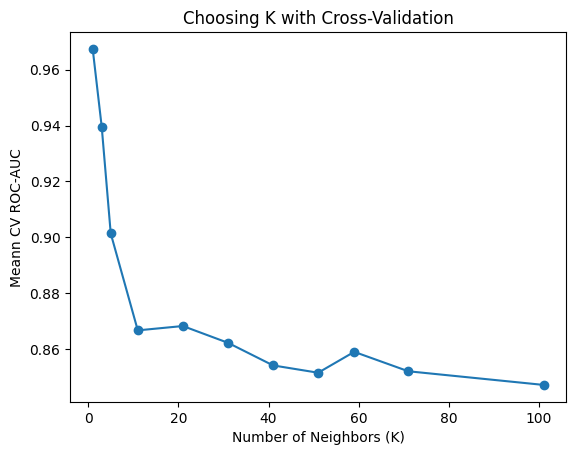

In [61]:
plt.plot(
    k_values,
    cv_scores,
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Meann CV ROC-AUC")
plt.title("Choosing K with Cross-Validation")

plt.show()

Based on the graph the best K-Value is 59.

In [20]:
from sklearn.metrics import accuracy_score

best_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=59)
)

best_knn.fit(X_train, y_train)
best_knn_pred = best_knn.predict(X_test)
accuracy_score(y_test, best_knn_pred)



0.7937743190661478

Based on the cross validation scores KNN would work the best when k = 59.

In [69]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


knn_cm = confusion_matrix(y_test, best_knn_pred)
print(knn_cm)

TN_knn, FP_knn, FN_knn, TP_knn = knn_cm.ravel()

print(f"\nMetrics:")
print(f"(TN): {TN_knn}")
print(f"(FP): {FP_knn}")
print(f" (FN): {FN_knn}")
print(f"(TP): {TP_knn}")


accuracy = accuracy_score(
    y_test_labels,
    pred_50_labels
)

precision = precision_score(
    y_test_labels,
    pred_50_labels,
    pos_label="Yes"
)

recall = recall_score(
    y_test_labels,
    pred_50_labels,
    pos_label="Yes"
)

specificity = TN / (TN + FP)

f1 = f1_score(
    y_test_labels,
    pred_50_labels,
    pos_label="Yes"
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)



[[ 95  33]
 [ 20 109]]

Metrics:
(TN): 95
(FP): 33
 (FN): 20
(TP): 109
Accuracy: 0.7470817120622568
Precision: 0.7253521126760564
Recall: 0.7984496124031008
Specificity: 0.6953125
F1: 0.7601476014760148


LOGISTIC

In [52]:
# Week 3, Part 4: fit the model
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression()

logreg.fit(X_train, y_train)

LogisticRegression()

In [57]:
logreg_prob= prob_heart
prob_heart = logreg.predict_proba(X_test)[:, 1]
#[:,1] means all rows (:) and the second column (1) (the probability that target = 1)

pred_50 = logreg.predict(X_test)

In [58]:
# Week 3: table comparing the results
results = X_test.copy()

results["Actual"] = y_test.values
results["P(Disease)"] = prob_heart
results["Prediction_0.50"] = pred_50

results.head(15)

,age,thalach,cp,fbs,sex,Actual,P(Disease),Prediction_0.50
383,58,111,0,0,1,0,0.071393,0
776,61,146,0,0,0,0,0.539842,1
792,68,141,0,1,1,0,0.084390,0
131,51,149,2,0,0,1,0.922356,1
464,67,160,2,0,0,1,0.889227,1
588,61,146,0,0,0,0,0.539842,1
734,52,156,0,1,1,0,0.237300,0
840,70,125,0,0,1,0,0.064341,0
456,47,152,2,0,1,0,0.731294,1
933,38,182,3,0,1,0,0.962598,1


In [59]:
from sklearn.metrics import confusion_matrix

confusion_matrix(
    results["Actual"],
    results["Prediction_0.50"])

array([[ 88,  40],
       [ 23, 106]])

In [28]:
import numpy as np

# Correctly reference the column inside the 'results' DataFrame
pred_50_labels = np.where(
    results["Prediction_0.50"] >= 0.50,
    "Yes",
    "No"
)


y_test_labels = np.where(y_test == 1, "Yes", "No")

# Confusion Matrix
cm = confusion_matrix(
    y_test_labels,
    pred_50_labels,
    labels=["No", "Yes"]
)

print("Confusion Matrix:")
print(cm)

TN, FP, FN, TP = cm.ravel()

print("\nMetrics:")
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

Confusion Matrix:
[[ 88  40]
 [ 23 106]]

Metrics:
TN: 88
FP: 40
FN: 23
TP: 106


In [30]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score)

accuracy = accuracy_score(
    y_test_labels,
    pred_50_labels
)

precision = precision_score(
    y_test_labels,
    pred_50_labels,
    pos_label="Yes"
)

recall = recall_score(
    y_test_labels,
    pred_50_labels,
    pos_label="Yes"
)

specificity = TN / (TN + FP)

f1 = f1_score(
    y_test_labels,
    pred_50_labels,
    pos_label="Yes"
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)

Accuracy: 0.754863813229572
Precision: 0.726027397260274
Recall: 0.8217054263565892
Specificity: 0.6875
F1: 0.7709090909090909


LDA

In [24]:
#Create model
lda = LinearDiscriminantAnalysis()

#Fit the model
lda.fit(X_train, y_train)

#Make prediction
lda_pred = lda.predict(X_test)

In [36]:
from sklearn.metrics import confusion_matrix

print("lda accuracy:", accuracy_score(y_test, lda_pred))
print("lda confusion matrix:")
print(confusion_matrix(y_test, lda_pred, labels=[1, 0]))

lda accuracy: 0.7587548638132295
lda confusion matrix:
[[108  21]
 [ 41  87]]


In [37]:
# Correctly reference the column inside the 'results' DataFrame
lda_prob = lda.predict_proba(X_test)[:, 1]

pred_50_labels = np.where(
    lda_prob >= 0.50,
    "Yes",
    "No"
)

y_test_labels = np.where(y_test == 1, "Yes", "No")

# Confusion Matrix
cm = confusion_matrix(
    y_test_labels,
    pred_50_labels,
    labels=["No", "Yes"]
)

print("Confusion Matrix:")
print(cm)

TN, FP, FN, TP = cm.ravel()

print("\nMetrics:")
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

Confusion Matrix:
[[ 87  41]
 [ 21 108]]

Metrics:
TN: 87
FP: 41
FN: 21
TP: 108


In [38]:
accuracy = accuracy_score(
    y_test_labels,
    pred_50_labels
)

precision = precision_score(
    y_test_labels,
    pred_50_labels,
    pos_label="Yes"
)

recall = recall_score(
    y_test_labels,
    pred_50_labels,
    pos_label="Yes"
)

specificity = TN / (TN + FP)

f1 = f1_score(
    y_test_labels,
    pred_50_labels,
    pos_label="Yes"
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)

Accuracy: 0.7587548638132295
Precision: 0.7248322147651006
Recall: 0.8372093023255814
Specificity: 0.6796875
F1: 0.7769784172661871


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Use the pre-calculated QDA probabilities we obtained earlier
# qda_prob represents predict_proba(X_test)[:, 1]

# 2. Calculate the ROC curve and AUC score using the original numeric y_test
fpr, tpr, thresholds = roc_curve(y_test, qda_prob)
auc_score = roc_auc_score(y_test, qda_prob)

# 3. Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(
    fpr,
    tpr,
    color="blue",
    label=f"QDA (AUC = {auc_score:.4f})"
)

# Plot the reference diagonal line representing random guessing
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="red"
)

plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.title("QDA ROC Curve")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

plt.show()

QDA

In [39]:
#Create model
qda = QuadraticDiscriminantAnalysis()

#Fit the model
qda.fit(X_train, y_train)

#Make prediction
qda_pred = qda.predict(X_test)

In [40]:
print("qda accuracy:", accuracy_score(y_test, qda_pred))
print("qda confusion matrix:")
print(confusion_matrix(y_test, qda_pred, labels=[1, 0]))

qda accuracy: 0.7470817120622568
qda confusion matrix:
[[103  26]
 [ 39  89]]


In [41]:
qda_prob = qda.predict_proba(X_test)[:, 1]

pred_50_labels = np.where(
    qda_prob >= 0.50,
    "Yes",
    "No"
)

y_test_labels = np.where(y_test == 1, "Yes", "No")

# Confusion Matrix
cm = confusion_matrix(
    y_test_labels,
    pred_50_labels,
    labels=["No", "Yes"]
)

print("Confusion Matrix:")
print(cm)

TN, FP, FN, TP = cm.ravel()

print("\nMetrics:")
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

Confusion Matrix:
[[ 89  39]
 [ 26 103]]

Metrics:
TN: 89
FP: 39
FN: 26
TP: 103


In [42]:
accuracy = accuracy_score(
    y_test_labels,
    pred_50_labels
)

precision = precision_score(
    y_test_labels,
    pred_50_labels,
    pos_label="Yes"
)

recall = recall_score(
    y_test_labels,
    pred_50_labels,
    pos_label="Yes"
)

specificity = TN / (TN + FP)

f1 = f1_score(
    y_test_labels,
    pred_50_labels,
    pos_label="Yes"
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)

Accuracy: 0.7470817120622568
Precision: 0.7253521126760564
Recall: 0.7984496124031008
Specificity: 0.6953125
F1: 0.7601476014760148


Part 5 Reflect:
So based on the Accuracy Precision Recall Specificity and F1 scores, as well as the least amount of False Positives we get, KNN looks like the best model, when K=59. Now a close second is LDA with only one more false negative than KNN. I chose to have only a 50% threshold for both LDA, and Logistic Regression because of the severity of getting something wrong. Although, the recall for the KNN seems to be the lowest out of all of the models, which is important because recall helps find those false negative.

Part 6

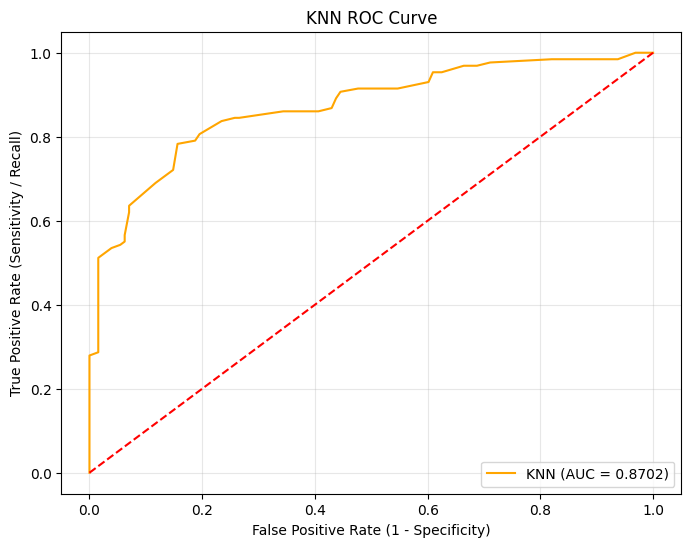

In [51]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# --- 3. KNN ROC Curve ---
# Get prediction probabilities for the tuned KNN model
knn_prob = best_knn.predict_proba(X_test)[:, 1]

# Calculate the ROC curve and AUC score using the original numeric y_test and KNN probabilities
fpr_knn, tpr_knn, thresholds_knn = roc_curve(y_test, knn_prob)
auc_score_knn = roc_auc_score(y_test, knn_prob)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(
    fpr_knn,
    tpr_knn,
    color="orange",
    label=f"KNN (AUC = {auc_score_knn:.4f})"
)

# Plot the reference diagonal line representing random guessing
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="red"
)

plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.title("KNN ROC Curve")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

plt.show()

In [65]:
# KNN
knn_prob = best_knn.predict_proba(X_test)[:, 1]
auc_knn = roc_auc_score(y_test, knn_prob)
print("KNN AUC:", auc_knn)

KNN AUC: 0.8702156007751938


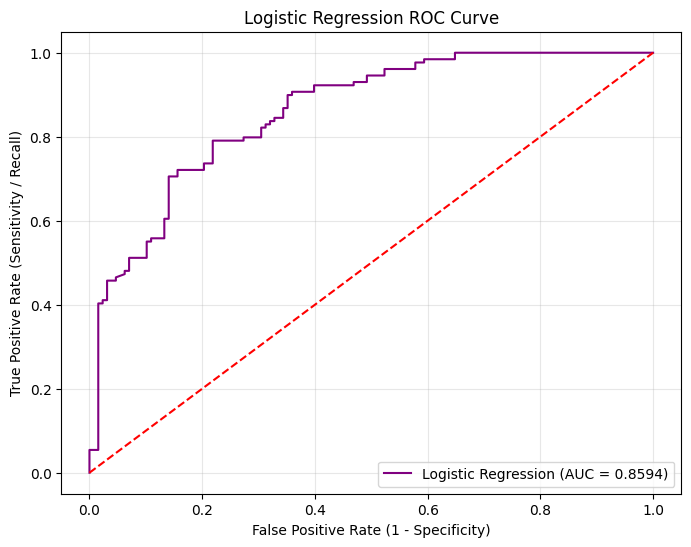

In [50]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# --- 2. Logistic Regression ROC Curve ---
# Calculate the ROC curve and AUC score using the original numeric y_test and Logistic Regression probabilities
fpr_log, tpr_log, thresholds_log = roc_curve(y_test, logreg_prob)
auc_score_log = roc_auc_score(y_test, logreg_prob)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(
    fpr_log,
    tpr_log,
    color="purple",
    label=f"Logistic Regression (AUC = {auc_score_log:.4f})"
)

# Plot the reference diagonal line representing random guessing
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="red"
)

plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.title("Logistic Regression ROC Curve")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

plt.show()

In [62]:
# Logistic Regression
auc_logreg = roc_auc_score(y_test, logreg_prob)
print("Logistic Regression AUC:", auc_logreg)

Logistic Regression AUC: 0.859375


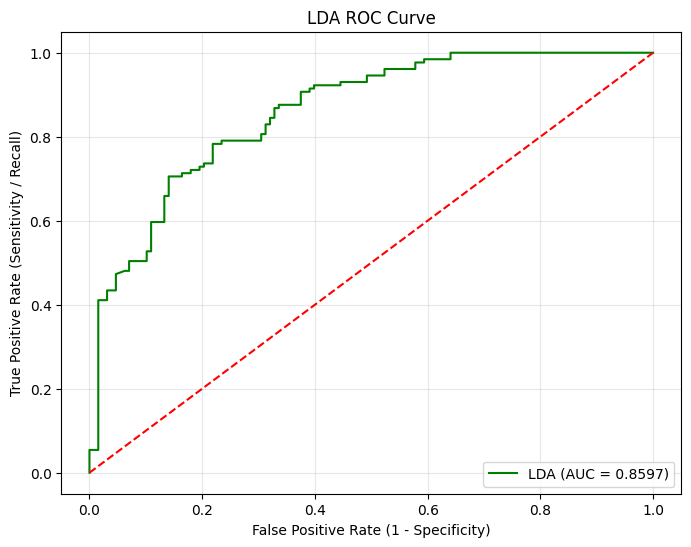

In [49]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# --- 1. LDA ROC Curve ---
# Calculate the ROC curve and AUC score using the original numeric y_test and LDA probabilities
fpr_lda, tpr_lda, thresholds_lda = roc_curve(y_test, lda_prob)
auc_score_lda = roc_auc_score(y_test, lda_prob)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(
    fpr_lda,
    tpr_lda,
    color="green",
    label=f"LDA (AUC = {auc_score_lda:.4f})"
)

# Plot the reference diagonal line representing random guessing
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="red"
)

plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.title("LDA ROC Curve")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

plt.show()

In [63]:
# LDA
auc_lda = roc_auc_score(y_test, lda_prob)
print("LDA AUC:", auc_lda)

LDA AUC: 0.8596778100775193


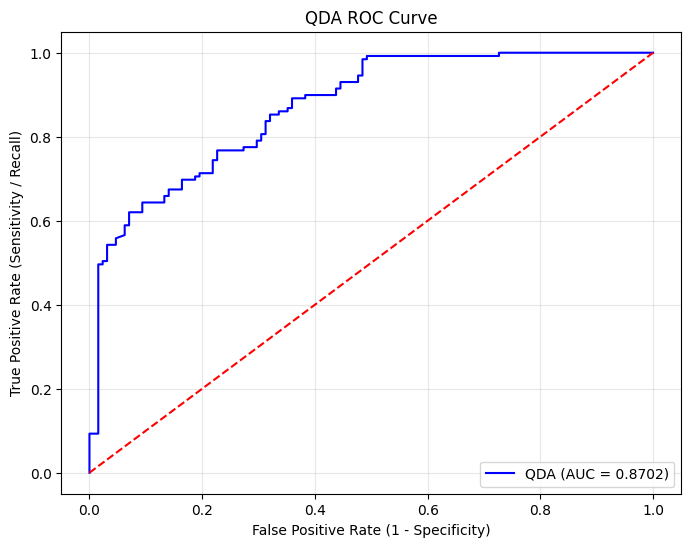

In [60]:


# 1. Use the pre-calculated QDA probabilities we obtained earlier
# qda_prob represents predict_proba(X_test)[:, 1]

# 2. Calculate the ROC curve and AUC score using the original numeric y_test
fpr, tpr, thresholds = roc_curve(y_test, qda_prob)
auc_score = roc_auc_score(y_test, qda_prob)

# 3. Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(
    fpr,
    tpr,
    color="blue",
    label=f"QDA (AUC = {auc_score:.4f})"
)

# Plot the reference diagonal line representing random guessing
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="red"
)

plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.title("QDA ROC Curve")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

plt.show()

In [64]:
# QDA
auc_qda = roc_auc_score(y_test, qda_prob)
print("QDA AUC:", auc_qda)

QDA AUC: 0.8702156007751938


Both KNN and QDA achieved the highest discriminative ability on this test set with identical AUCs of 0.8702, followed closely by the linear methods (LDA and Logistic Regression). All models demonstrate strong predictive capability for heart disease classification.

Part 7:
Comparing the performace of all the models we can very much see that they all work pretty well and can stand on their own. What edges out with KNN mostly is due to its low False Negatives, and the highest AUC score tied with QDA. Although the recall score was one of the lowest out of all the models KNN, with the K= 59 actually does pretty well and seems to be the strongest out of the bunch, although it is very complex and would take up a lot of memery and storage from the computer.

Based on all of this however I think that LDA would be the best fit, although it isn't the best out of all of the 4, it is still pretty close, and it had only 23 false negatives which was the second lowest. I feel like making sure that we are more efficient in our models will help out a lot and I feel like that should be a priority.

A limitation that I had with my model was that there was an assumption right from the start that there might have been some duplicate models, and that might've changed up how the data looked. A part from that the dataset was actually pretty well cleaned up and there wasn't any need for encoding or changing any varibles, although cp was something that might've needed to be changed I didn't because it didn't seem as necessary.